# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

**Identitas Mahasiswa**
- Nama: Reynaldi Adi Putra Vetryanto
- NIM: 241011402619
- Kelas: 05TPLE005 
Implementasi model dan metrik utama dibuat menggunakan NumPy. Scikit-learn hanya digunakan pada bagian bonus.


## Ketentuan dan dataset
- `Ads_Data.csv`: biaya iklan dan penjualan (40 baris).
- `Email_Data.csv`: jumlah link, kata promosi, dan label spam (60 baris).
- `RANDOM_STATE` menggunakan dua digit terakhir NIM, yaitu **19**.


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 19
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (7, 4)

def train_test_split_np(X, y, test_size=0.2, random_state=19):
    # Meniru pembagian acak: sejumlah data testing diambil dari awal permutasi.
    n = len(X)
    n_test = int(np.ceil(n * test_size))
    indices = np.random.RandomState(random_state).permutation(n)
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

def confusion_matrix_np(y_true, y_pred):
    # Urutan baris/kolom: kelas 0 lalu kelas 1.
    cm = np.zeros((2, 2), dtype=int)
    for actual, predicted in zip(np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)):
        cm[actual, predicted] += 1
    return cm

def accuracy_score_np(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))

def precision_recall_f1_np(y_true, y_pred):
    cm = confusion_matrix_np(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return precision, recall, f1, cm


---
# Bagian A – Linear Regression (35%)
## A1 – Load & Visualisasi Data
Baca data, tampilkan lima baris pertama dan jumlah baris, pisahkan X/y, serta buat scatter plot.


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris: 40
Shape X: (40, 1) | Shape y: (40,)


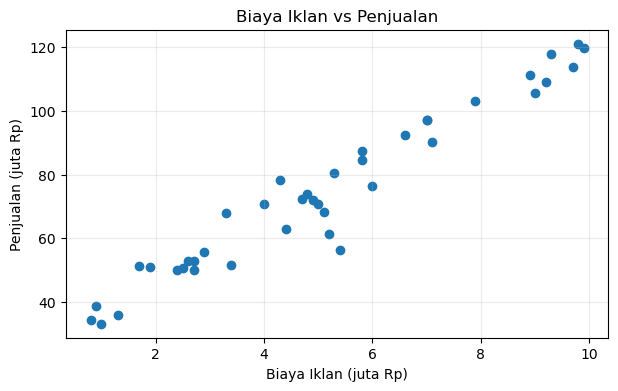

In [17]:
ads = pd.read_csv("Ads_Data.csv")
display(ads.head())
print("Jumlah baris:", len(ads))

X_ads = ads[["BiayaIklan"]].to_numpy(dtype=float)  # bentuk (n, 1)
y_ads = ads["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X_ads.shape, "| Shape y:", y_ads.shape)

plt.scatter(X_ads[:, 0], y_ads)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.25)
plt.show()


## A2 – Split Data
Bagi data dengan `test_size=0.2` dan `random_state=19`.


In [18]:
X_train, X_test, y_train, y_test = train_test_split_np(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


## A3 – Training dengan Normal Equation
Model: ŷ = b + mX. Intercept dan koefisien dihitung dengan persamaan normal.


In [19]:
def fit_linear_normal_equation(X, y):
    X_bias = np.c_[np.ones(len(X)), X]
    theta = np.linalg.pinv(X_bias.T @ X_bias) @ X_bias.T @ y
    return theta[0], theta[1:]

def predict_linear(X, intercept, coef):
    return intercept + X @ coef

intercept, coef = fit_linear_normal_equation(X_train, y_train)
print(f"Intercept (b): {intercept:.4f}")
print(f"Koefisien (m): {coef[0]:.4f}")
print(f"Persamaan regresi: ŷ = {intercept:.4f} + {coef[0]:.4f}X")


Intercept (b): 27.7178
Koefisien (m): 9.1255
Persamaan regresi: ŷ = 27.7178 + 9.1255X


**Jawaban A3 (interpretasi):**

Nilai koefisien menunjukkan perkiraan perubahan penjualan untuk setiap kenaikan biaya iklan sebesar Rp1 juta. Karena koefisien yang dihasilkan positif, model memperkirakan bahwa biaya iklan yang lebih tinggi berkaitan dengan penjualan yang lebih tinggi. Ini merupakan hubungan pada data, bukan bukti bahwa iklan satu-satunya penyebab perubahan penjualan.


## A4 – Evaluasi Model
Hitung MAE, MSE, RMSE, dan R² secara manual dengan NumPy untuk data training dan testing.


In [20]:
def regression_metrics(y_true, y_pred):
    errors = np.asarray(y_true) - np.asarray(y_pred)
    mae = np.mean(np.abs(errors))
    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)
    denominator = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - np.sum(errors ** 2) / denominator if denominator != 0 else np.nan
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

pred_train = predict_linear(X_train, intercept, coef)
pred_test = predict_linear(X_test, intercept, coef)
metrics_table = pd.DataFrame([
    {"Data": "Training", **regression_metrics(y_train, pred_train)},
    {"Data": "Testing", **regression_metrics(y_test, pred_test)}
]).set_index("Data")
display(metrics_table.round(4))


,MAE,MSE,RMSE,R2
Data,,,,
Training,4.9622,41.9134,6.4741,0.9340
Testing,2.9401,13.3969,3.6602,0.9788


**Jawaban A4 (analisis):**

MAE adalah rata-rata selisih absolut antara penjualan aktual dan prediksi, sedangkan RMSE memberi penalti lebih besar pada kesalahan yang besar. Nilai R² mengukur seberapa baik model menjelaskan variasi penjualan; nilai yang mendekati 1 umumnya menunjukkan kecocokan yang lebih baik. Gunakan angka tabel di atas untuk menilai hasil testing: jika RMSE testing masih besar dibanding rentang penjualan atau R² rendah/negatif, model belum cukup baik. Perbedaan besar antara training dan testing dapat menandakan generalisasi yang kurang baik.


## A5 – Gradient Descent & Learning Rate
Latih model selama 5.000 iterasi untuk learning rate 0.001, 0.02, dan 0.1. Data tidak dinormalisasi agar eksperimen memperlihatkan pengaruh learning rate sebagaimana diminta.


learning_rate=0.001: intercept=24.492352929178626, koefisien=[9.623], iterasi=5000, loss akhir=44.12334918414545
learning_rate=0.02: intercept=27.717760948304054, koefisien=[9.1255], iterasi=5000, loss akhir=41.913364943474924
learning_rate=0.1: intercept=1.5357126054735747e+305, koefisien=[inf], iterasi=397, loss akhir=inf


/var/folders/cz/tw6y07_s50z1gmk8v8h1d7yr0000gn/T/ipykernel_14805/43477869.py:7: RuntimeWarning: overflow encountered in matmul
  gradient = (2 / len(y)) * (X_bias.T @ errors)
/opt/anaconda3/lib/python3.13/site-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


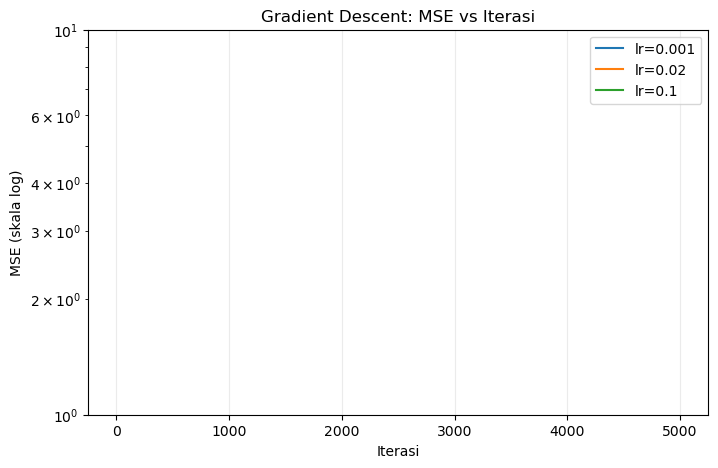

In [21]:
def fit_linear_gd(X, y, learning_rate, n_iterations=5000):
    X_bias = np.c_[np.ones(len(X)), X]
    theta = np.zeros(X_bias.shape[1], dtype=float)
    losses = []
    for _ in range(n_iterations):
        errors = X_bias @ theta - y
        gradient = (2 / len(y)) * (X_bias.T @ errors)
        theta = theta - learning_rate * gradient
        with np.errstate(over="ignore", invalid="ignore"):
            loss = np.mean((X_bias @ theta - y) ** 2)
        losses.append(loss)
        if not np.all(np.isfinite(theta)):
            # Simpan NaN/inf sebagai tanda divergensi; tidak menghentikan eksperimen lain.
            break
    return theta[0], theta[1:], np.asarray(losses)

gd_results = {}
for lr in [0.001, 0.02, 0.1]:
    b_gd, m_gd, losses = fit_linear_gd(X_train, y_train, lr, n_iterations=5000)
    gd_results[lr] = (b_gd, m_gd, losses)
    final_loss = losses[-1] if len(losses) else np.nan
    print(f"learning_rate={lr}: intercept={b_gd}, koefisien={m_gd}, iterasi={len(losses)}, loss akhir={final_loss}")

plt.figure(figsize=(8, 5))
for lr, (_, _, losses) in gd_results.items():
    finite = np.isfinite(losses) & (losses > 0)
    if finite.any():
        plt.plot(np.arange(1, len(losses)+1)[finite], losses[finite], label=f"lr={lr}")
plt.yscale("log")
plt.title("Gradient Descent: MSE vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("MSE (skala log)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


**Jawaban A5 (analisis):**

Bandingkan loss akhir dan koefisien dengan hasil Normal Equation di A3. Learning rate 0.001 biasanya bergerak lebih lambat menuju solusi. Learning rate 0.02 pada dataset ini diharapkan lebih cepat mendekati solusi. Learning rate 0.1 terlalu besar untuk skala fitur mentah ini sehingga parameter dapat melonjak, menghasilkan overflow, lalu divergen (nilai tak hingga/NaN). Divergensi terjadi karena langkah pembaruan terlalu besar sehingga tidak menuju nilai minimum loss.


## A6 – Visualisasi & Prediksi
Tampilkan data testing dengan garis model dan prediksi untuk biaya iklan 4.5, 7, dan 12 juta rupiah.


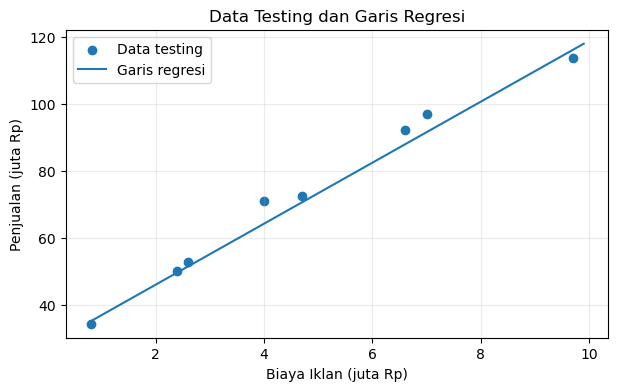

,BiayaIklan (juta Rp),PrediksiPenjualan (juta Rp)
0,4.5,68.782
1,7.0,91.596
2,12.0,137.224


In [22]:
plt.scatter(X_test[:, 0], y_test, label="Data testing")
x_line = np.linspace(float(X_ads.min()), float(X_ads.max()), 100).reshape(-1, 1)
plt.plot(x_line[:, 0], predict_linear(x_line, intercept, coef), label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_baru = predict_linear(biaya_baru, intercept, coef)
display(pd.DataFrame({
    "BiayaIklan (juta Rp)": biaya_baru[:, 0],
    "PrediksiPenjualan (juta Rp)": prediksi_baru
}).round(3))


**Jawaban A6 (analisis):**

Prediksi untuk biaya iklan 4,5 dan 7 juta berada dalam rentang biaya iklan pada dataset, sehingga relatif lebih dekat dengan data yang dipelajari model. Prediksi untuk 12 juta merupakan ekstrapolasi karena melebihi nilai maksimum dataset (9,9 juta). Hasil ekstrapolasi lebih tidak pasti karena hubungan linear yang terlihat pada data belum tentu berlanjut di luar rentang pengamatan.


---
# Bagian B – Logistic Regression (40%)
## B1 – Load & Visualisasi Data


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email per kelas:
Spam
Bukan Spam    35
Spam          25
Name: count, dtype: int64
Shape X: (60, 2) | Shape y: (60,)


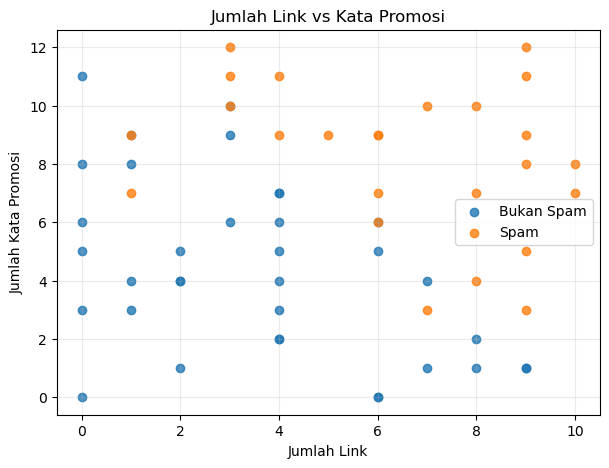

In [23]:
email = pd.read_csv("Email_Data.csv")
display(email.head())
print("Jumlah email per kelas:")
print(email["Spam"].map({0: "Bukan Spam", 1: "Spam"}).value_counts())

X_email = email[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = email["Spam"].to_numpy(dtype=int)
print("Shape X:", X_email.shape, "| Shape y:", y_email.shape)

plt.figure(figsize=(7, 5))
for label, name in [(0, "Bukan Spam"), (1, "Spam")]:
    mask = y_email == label
    plt.scatter(X_email[mask, 0], X_email[mask, 1], label=name, alpha=0.8)
plt.title("Jumlah Link vs Kata Promosi")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promosi")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## B2 – Split Data & Training
Model Logistic Regression dibuat dengan gradient descent dan log loss. Fitur dipakai sesuai skala asli dataset.


X_train: (45, 2) | X_test: (15, 2)
y_train: (45,) | y_test: (15,)
Intercept (b): -8.4097
Koefisien m1 (JumlahLink): 0.7272
Koefisien m2 (KataPromo): 0.7292
P(Spam) = sigmoid(-8.4097 + (0.7272 * JumlahLink) + (0.7292 * KataPromo))


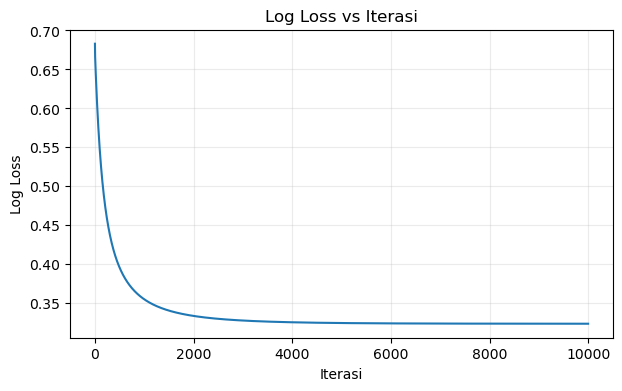

Log loss awal: 0.683
Log loss akhir: 0.3236


In [24]:
Xtr_email, Xte_email, ytr_email, yte_email = train_test_split_np(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
print("X_train:", Xtr_email.shape, "| X_test:", Xte_email.shape)
print("y_train:", ytr_email.shape, "| y_test:", yte_email.shape)

def sigmoid(z):
    z = np.clip(z, -500, 500)  # mencegah overflow eksponensial
    return 1 / (1 + np.exp(-z))

def fit_logistic_gd(X, y, learning_rate=0.1, n_iterations=10000):
    X_bias = np.c_[np.ones(len(X)), X]
    theta = np.zeros(X_bias.shape[1], dtype=float)
    losses = []
    for _ in range(n_iterations):
        probabilities = sigmoid(X_bias @ theta)
        gradient = X_bias.T @ (probabilities - y) / len(y)
        theta -= learning_rate * gradient
        p = np.clip(sigmoid(X_bias @ theta), 1e-12, 1 - 1e-12)
        loss = -np.mean(y * np.log(p) + (1-y) * np.log(1-p))
        losses.append(loss)
    return theta[0], theta[1:], np.asarray(losses)

def predict_proba_logistic(X, intercept, coef):
    return sigmoid(intercept + X @ coef)

b_log, m_log, log_losses = fit_logistic_gd(
    Xtr_email, ytr_email, learning_rate=0.1, n_iterations=10000
)
print(f"Intercept (b): {b_log:.4f}")
print(f"Koefisien m1 (JumlahLink): {m_log[0]:.4f}")
print(f"Koefisien m2 (KataPromo): {m_log[1]:.4f}")
print(f"P(Spam) = sigmoid({b_log:.4f} + ({m_log[0]:.4f} * JumlahLink) + ({m_log[1]:.4f} * KataPromo))")

plt.plot(log_losses)
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.grid(alpha=0.25)
plt.show()
print("Log loss awal:", round(float(log_losses[0]), 4))
print("Log loss akhir:", round(float(log_losses[-1]), 4))


**Jawaban B2 (analisis):**

Jika grafik log loss menurun lalu cenderung mendatar, model sedang belajar dan mendekati keadaan stabil. Intercept adalah nilai dasar pada persamaan, sedangkan koefisien menunjukkan perubahan skor logit ketika jumlah link atau kata promosi bertambah satu, dengan fitur lainnya tetap. Probabilitas spam diperoleh melalui fungsi sigmoid yang mengubah skor menjadi nilai antara 0 dan 1.


## B3 – Evaluasi Model


In [25]:
prob_test = predict_proba_logistic(Xte_email, b_log, m_log)
pred_test_email = (prob_test >= 0.5).astype(int)
precision, recall, f1, cm = precision_recall_f1_np(yte_email, pred_test_email)
accuracy = accuracy_score_np(yte_email, pred_test_email)
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix (baris aktual 0/1, kolom prediksi 0/1):")
print(cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")


Confusion matrix (baris aktual 0/1, kolom prediksi 0/1):
[[10  0]
 [ 0  5]]
TN=10, FP=0, FN=0, TP=5
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000


**Jawaban B3 (analisis):**

False Positive (FP) adalah email bukan spam yang salah ditandai sebagai spam. False Negative (FN) adalah email spam yang lolos dan dianggap bukan spam. Untuk sebagian pengguna, FN dapat merugikan karena pesan penipuan atau promosi spam masuk ke kotak masuk; namun FP juga serius karena email penting dapat masuk ke folder spam. Pilihan yang lebih merugikan bergantung pada kebutuhan pengguna dan seberapa besar risiko kehilangan email penting dibandingkan menerima spam.


## B4 – Decision Boundary


KataPromo = -(-8.4097 + (0.7272 * JumlahLink)) / (0.7292)


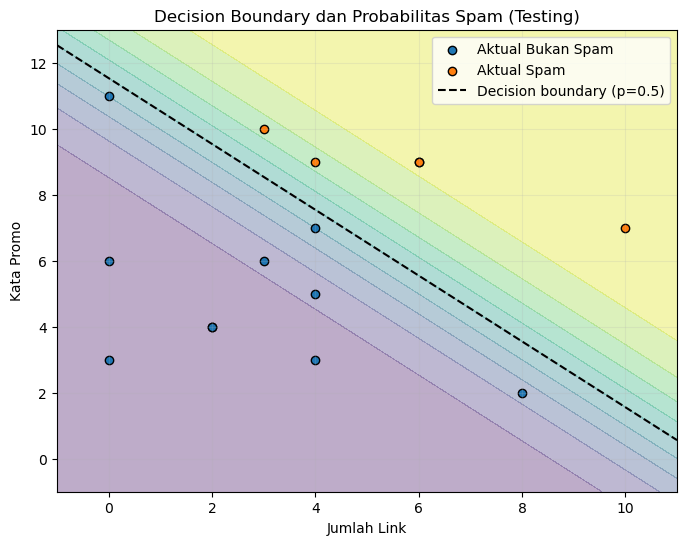

Data testing yang salah diklasifikasikan:


,JumlahLink,KataPromo,Aktual,Prediksi


In [26]:
# Decision boundary: b + m1*x1 + m2*x2 = 0
if abs(m_log[1]) > 1e-12:
    print(f"KataPromo = -({b_log:.4f} + ({m_log[0]:.4f} * JumlahLink)) / ({m_log[1]:.4f})")
else:
    print("Koefisien KataPromo mendekati nol; garis batas vertikal/tidak stabil untuk ditulis sebagai x2.")

x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 200), np.linspace(x2_min, x2_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = predict_proba_logistic(grid, b_log, m_log).reshape(xx.shape)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, levels=np.linspace(0, 1, 11), alpha=0.35)
for label, name in [(0, "Bukan Spam"), (1, "Spam")]:
    mask = yte_email == label
    plt.scatter(Xte_email[mask, 0], Xte_email[mask, 1], label=f"Aktual {name}", edgecolor="black")
if abs(m_log[1]) > 1e-12:
    x1_line = np.linspace(x1_min, x1_max, 200)
    x2_line = -(b_log + m_log[0] * x1_line) / m_log[1]
    plt.plot(x1_line, x2_line, "k--", label="Decision boundary (p=0.5)")
wrong = pred_test_email != yte_email
if np.any(wrong):
    plt.scatter(Xte_email[wrong, 0], Xte_email[wrong, 1], s=150, facecolors="none", edgecolors="red", linewidths=2, label="Salah klasifikasi")
plt.title("Decision Boundary dan Probabilitas Spam (Testing)")
plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

wrong_df = pd.DataFrame(Xte_email[wrong], columns=["JumlahLink", "KataPromo"])
wrong_df["Aktual"] = yte_email[wrong]
wrong_df["Prediksi"] = pred_test_email[wrong]
print("Data testing yang salah diklasifikasikan:")
display(wrong_df if len(wrong_df) else pd.DataFrame(columns=["JumlahLink","KataPromo","Aktual","Prediksi"]))


**Jawaban B4 (analisis):**

Decision boundary adalah garis ketika probabilitas spam sama dengan 0,5. Titik yang dilingkari merah pada grafik adalah data testing yang prediksinya berbeda dari label sebenarnya. Jika tidak ada titik yang dilingkari, berarti semua data testing pada pembagian ini diklasifikasikan dengan benar.


## B5 – Eksperimen Threshold


In [27]:
threshold_rows = []
threshold_predictions = {}
for threshold in [0.3, 0.5, 0.7]:
    pred = (prob_test >= threshold).astype(int)
    p, r, f, cm_t = precision_recall_f1_np(yte_email, pred)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    threshold_predictions[threshold] = pred
    threshold_rows.append({
        "Threshold": threshold, "TN": tn_t, "FP": fp_t, "FN": fn_t, "TP": tp_t,
        "Precision": p, "Recall": r, "F1": f
    })
threshold_table = pd.DataFrame(threshold_rows).set_index("Threshold")
display(threshold_table.round(4))


,TN,FP,FN,TP,Precision,Recall,F1
Threshold,,,,,,,
0.3,8,2,0,5,0.7143,1.0,0.8333
0.5,10,0,0,5,1.0000,1.0,1.0000
0.7,10,0,0,5,1.0000,1.0,1.0000


**Jawaban B5 (analisis):**

Threshold lebih rendah membuat model lebih mudah memberi label spam, sehingga biasanya recall meningkat tetapi FP juga dapat bertambah dan precision dapat menurun. Threshold lebih tinggi membuat model lebih selektif menandai spam, sehingga biasanya precision meningkat tetapi sebagian spam dapat terlewat dan recall menurun. Pilih threshold berdasarkan tabel hasil Anda: jika tujuan utama adalah mengurangi spam yang lolos, utamakan recall; jika email penting sering salah masuk spam, pertimbangkan threshold lebih tinggi. Pada B6, gunakan threshold pilihan yang ditetapkan di bawah ini.


In [28]:
# Pilihan awal: 0.5 sebagai ambang standar. Ubah jika analisis tabel B5 mendukung pilihan lain.
CHOSEN_THRESHOLD = 0.5
print("Threshold yang digunakan untuk prediksi email baru:", CHOSEN_THRESHOLD)


Threshold yang digunakan untuk prediksi email baru: 0.5


## B6 – Prediksi Email Baru


In [29]:
new_emails = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})
X_new = new_emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
new_prob = predict_proba_logistic(X_new, b_log, m_log)
new_pred = (new_prob >= CHOSEN_THRESHOLD).astype(int)
new_emails["ProbabilitasSpam"] = new_prob
new_emails["PrediksiAngka"] = new_pred
new_emails["HasilPrediksi"] = np.where(new_pred == 1, "Spam", "Bukan Spam")
display(new_emails.round(4))


,Email,JumlahLink,KataPromo,ProbabilitasSpam,PrediksiAngka,HasilPrediksi
0,E1,1,2,0.0020,0,Bukan Spam
1,E2,5,6,0.4017,0,Bukan Spam
2,E3,9,10,0.9956,1,Spam
3,E4,2,11,0.7439,1,Spam


---
# Bagian C – Pemahaman Konsep
## Jawaban C1
Logistic Regression termasuk klasifikasi karena digunakan untuk memprediksi kelas, misalnya spam atau bukan spam. Model menghitung skor dari fitur, kemudian fungsi sigmoid mengubah skor tersebut menjadi probabilitas antara 0 dan 1. Probabilitas itu dibandingkan dengan threshold untuk menentukan kelas. Jadi, output probabilitasnya digunakan untuk memilih kategori, bukan memprediksi nilai kontinu seperti Linear Regression.

## Jawaban C2
Normal Equation menghitung parameter secara langsung menggunakan operasi matriks, tanpa melakukan iterasi pembaruan parameter. Gradient Descent memperbarui parameter sedikit demi sedikit berdasarkan gradien loss. Normal Equation praktis untuk dataset kecil dengan jumlah fitur sedikit, sedangkan Gradient Descent dapat lebih sesuai untuk dataset besar atau banyak fitur. Hasil Gradient Descent dipengaruhi learning rate dan jumlah iterasi.

## Jawaban C3
Data testing digunakan untuk mengukur kemampuan model pada data yang tidak dipakai saat pelatihan. Jika hanya mengevaluasi data training, nilai evaluasi bisa tampak baik karena model sudah menyesuaikan diri dengan data tersebut. Overfitting terjadi ketika model terlalu mengikuti pola atau noise data training sehingga kinerjanya menurun pada data baru. Karena itu, hasil testing lebih berguna untuk menilai kemampuan generalisasi.

## Jawaban C4
Linear Regression menghasilkan nilai kontinu, sehingga MSE menghitung rata-rata kuadrat selisih antara nilai aktual dan prediksi. Logistic Regression menghasilkan probabilitas untuk kelas, sehingga log loss menilai seberapa baik probabilitas tersebut sesuai dengan label sebenarnya. Log loss memberi penalti besar ketika model memberikan probabilitas sangat yakin tetapi salah. Metrik loss dipilih sesuai jenis output dan tujuan model.

## Jawaban C5
Hasil dapat berbeda jika pembagian training dan testing berbeda, misalnya karena nilai `random_state` yang berbeda. Parameter awal, learning rate, jumlah iterasi, skala fitur, dan cara implementasi algoritma juga dapat memengaruhi hasil. Pada Logistic Regression, perbedaan pengaturan regularisasi atau kriteria berhenti dapat menghasilkan koefisien berbeda. Karena itu, pengaturan eksperimen harus dicatat agar perbandingan adil.


---
# Bonus (+5) – Perbandingan dengan scikit-learn
Bagian ini opsional dan satu-satunya bagian yang diperbolehkan memakai scikit-learn. Jalankan jika library tersedia.


In [31]:
try:
    from sklearn.linear_model import LinearRegression as SklearnLinearRegression
    from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

    sk_lin = SklearnLinearRegression().fit(X_train, y_train)
    sk_pred = sk_lin.predict(X_test)
    print("Linear Regression scikit-learn")
    print("Intercept:", sk_lin.intercept_, "| Koefisien:", sk_lin.coef_)
    print("Metrik testing:", regression_metrics(y_test, sk_pred))

    # Logistic Regression sklearn menggunakan regularisasi default.
    sk_log = SklearnLogisticRegression(max_iter=10000, random_state=RANDOM_STATE)
    sk_log.fit(Xtr_email, ytr_email)
    sk_pred_email = sk_log.predict(Xte_email)
    print("\nLogistic Regression scikit-learn")
    print("Intercept:", sk_log.intercept_[0], "| Koefisien:", sk_log.coef_[0])
    print("Accuracy:", accuracy_score_np(yte_email, sk_pred_email))
    print("Confusion matrix:\n", confusion_matrix_np(yte_email, sk_pred_email))
except ImportError:
    print("scikit-learn belum terpasang. Bagian bonus dilewati; bagian utama tetap menggunakan NumPy.")


Linear Regression scikit-learn
Intercept: 27.717760948304225 | Koefisien: [9.1255]
Metrik testing: {'MAE': np.float64(2.9400765558116646), 'MSE': np.float64(13.396876739499113), 'RMSE': np.float64(3.660174413808598), 'R2': np.float64(0.9787735208414353)}

Logistic Regression scikit-learn
Intercept: -7.8110224118380644 | Koefisien: [0.6702 0.679 ]
Accuracy: 1.0
Confusion matrix:
 [[10  0]
 [ 0  5]]


**Jawaban Bonus (analisis):**

Linear Regression dari scikit-learn umumnya memberi hasil yang sangat dekat dengan implementasi Normal Equation karena keduanya mencari garis yang meminimalkan jumlah kuadrat error. Logistic Regression dapat memberi koefisien berbeda karena implementasi scikit-learn menerapkan regularisasi secara default dan memakai prosedur optimisasi yang berbeda. Parameter `C` mengatur kebalikan kekuatan regularisasi; nilai C lebih besar berarti regularisasi lebih lemah. Karena bagian ini bonus, jangan gunakan scikit-learn untuk menggantikan implementasi utama.


---
## Checklist sebelum dikumpulkan
- [ ] Pastikan kelas sudah dipilih: Reg B atau Reg C.
- [ ] Jalankan semua sel dari atas ke bawah dan pastikan tidak ada error.
- [ ] Periksa angka dan analisis berdasarkan output notebook sendiri.
- [ ] Unggah `tugas_UTS.ipynb`, `Ads_Data.csv`, `Email_Data.csv`, dan `README.md` ke repository GitHub Public bernama `uts-machine-learning-241011402619`.
- [ ] Kumpulkan link repository di Mentari sebelum tenggat kelas Anda.
